# PART 2 — CXR Arm: "Degradation as Biomarker or Shortcut?" (MIDL 2027)
**NIH Chest X-ray14 (train/val/test, patient-level splits) + Pediatric Pneumonia CXR (external OOD)**.

**Run in a FRESH notebook/session** (do not continue the fundus session). Add as input: `NIH Chest X-rays`, `Pediatric Pneumonia Chest X-ray`, AND the output of your fundus notebook (for the combined decision-rule figure — optional but recommended). Enable Internet (for `pyiqa`).

Task: **Pneumonia vs. no-pneumonia** (single-label binary, keeps the pipeline identical to the fundus arm).
Expected runtime: ~2–3 h training (12 runs) + ~10 min evaluation on one T4.

In [1]:
!pip install -q pyiqa timm

import os, sys, glob, json, time, random, warnings, fnmatch, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image, ImageEnhance, ImageFilter
from scipy import ndimage
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score, accuracy_score

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
WORK = '/kaggle/working'
for d in ['features_cxr', 'ckpt', 'results']:
    os.makedirs(f'{WORK}/{d}', exist_ok=True)
INPUT = '/kaggle/input'
N_NEG = 3000          # negatives sampled from NIH (all pneumonia positives kept)
VAL_FRAC, TEST_FRAC = 0.15, 0.15
print('device:', DEVICE)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 7.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 97.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.

## 1. Auto path & label discovery
- **NIH**: finds `Data_Entry_2017.csv` + `images_*` folders; detects the image-index column by filename match-rate; builds the binary Pneumonia label from `Finding Labels`; **splits by Patient ID** (no patient leakage).
- **Pediatric Pneumonia (Kermany)**: folder-based labels (`NORMAL`/`PNEUMONIA`), used as the external OOD set.
Everything detected is printed; asserts stop early with clear messages if anything is off — paste the printout if so.

In [2]:
def walk_input():
    for root, dirs, files in os.walk(INPUT):
        yield root, dirs, files

def find_dirs(patterns):
    hits = []
    for root, dirs, _ in walk_input():
        for d in dirs:
            if any(fnmatch.fnmatch(d.lower(), p) for p in patterns):
                hits.append(os.path.join(root, d))
    return hits

def find_files(patterns):
    hits = []
    for root, _, files in walk_input():
        for f in files:
            if any(fnmatch.fnmatch(f.lower(), p) for p in patterns):
                hits.append(os.path.join(root, f))
    return hits

IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')
def norm_id(v):
    v = os.path.basename(str(v).strip()).lower()
    v = os.path.splitext(v)[0]
    return ''.join(ch for ch in v if ch.isalnum())

# ---------- NIH ----------
nih_csvs = find_files(['data_entry*.csv'])
assert nih_csvs, 'Data_Entry_2017.csv not found - check the NIH dataset name.'
nih_csv = nih_csvs[0]
nih_root = os.path.dirname(nih_csv)
nih_img_dirs = find_dirs(['images_*'])
assert nih_img_dirs, 'no images_* folders found for NIH.'
nih_map = {}
for d in nih_img_dirs:
    for p in glob.glob(os.path.join(d, '**', '*.*'), recursive=True):
        if p.lower().endswith(IMG_EXT):
            nih_map[norm_id(p)] = p
print('NIH csv:', nih_csv)
print('NIH image dirs:', len(nih_img_dirs), '| images:', len(nih_map))

ndf = pd.read_csv(nih_csv)
print('NIH columns:', list(ndf.columns))

def pick_id_col(df, idmap):
    keys = set(idmap.keys())
    best_c, best_s = None, 0.0
    for c in df.columns:
        vals = df[c].astype(str).map(norm_id)
        s = float(vals.isin(keys).mean())
        if s > best_s:
            best_c, best_s = c, s
    return best_c, best_s

idc, rate = pick_id_col(ndf, nih_map)
print(f'NIH id column="{idc}" (match rate={rate:.1%})')
assert idc is not None and rate > 0.5, 'NIH: could not match CSV ids to image files - report the printed columns.'
ndf['_id'] = ndf[idc].astype(str).map(norm_id)
ndf = ndf[ndf['_id'].isin(set(nih_map))].copy()
ndf['path'] = ndf['_id'].map(nih_map)

# Finding Labels column
lab_col = None
for c in ndf.columns:
    s = ndf[c].astype(str)
    if s.str.contains('pneumonia', case=False).mean() > 0.005 and \
       (s.str.contains(r'\|', regex=True).mean() > 0.01 or (s == 'No Finding').mean() > 0.01):
        lab_col = c; break
print(f'NIH finding-labels column="{lab_col}"')
assert lab_col is not None, 'NIH: could not identify Finding Labels column - report the printed columns.'
ndf['label'] = ndf[lab_col].astype(str).str.contains('Pneumonia', case=False).astype(int)

# patient id (for grouped split); fall back to filename prefix
pat_col = next((c for c in ndf.columns if 'patient' in c.lower() and 'id' in c.lower()), None)
if pat_col is not None:
    ndf['patient'] = ndf[pat_col].astype(str)
else:
    ndf['patient'] = ndf['_id'].str[:8]
print(f'NIH patient column={"'" + pat_col + "'" if pat_col else "filename prefix"} | patients={ndf.patient.nunique()}')

# subsample: all positives + N_NEG negatives
pos = ndf[ndf.label == 1]
neg = ndf[ndf.label == 0].sample(min(N_NEG, int((ndf.label == 0).sum())), random_state=SEED)
sub = pd.concat([pos, neg]).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
print(f'NIH subsample: n={len(sub)}  pos={int(sub.label.sum())} ({sub.label.mean():.1%})')

# patient-grouped 70/15/15 split
rng = np.random.default_rng(SEED)
pats = sub.patient.unique(); rng.shuffle(pats)
n_p = len(pats)
i1, i2 = int(n_p * (1 - VAL_FRAC - TEST_FRAC)), int(n_p * (1 - TEST_FRAC))
g_tr, g_va, g_te = set(pats[:i1]), set(pats[i1:i2]), set(pats[i2:])

def mk(split_name, mask):
    d = sub[mask].copy()
    out = pd.DataFrame({'id': d['_id'], 'grade': d['label'].astype(float), 'path': d['path']})
    out['source'] = split_name
    out['label'] = d['label'].values
    return out.reset_index(drop=True)

tr, va, te = mk('cxr_train', sub.patient.isin(g_tr)), mk('cxr_val', sub.patient.isin(g_va)), mk('cxr_test', sub.patient.isin(g_te))

# ---------- Pediatric Pneumonia (Kermany) : external ----------
def find_kermany_root():
    for root, dirs, _ in walk_input():
        low = {d.lower() for d in dirs}
        if os.path.basename(root).lower() in ('train', 'test') and {'normal', 'pneumonia'} <= low:
            return os.path.dirname(root)
    return None

kroot = find_kermany_root()
assert kroot, 'Pediatric Pneumonia dataset not found (expected train/{NORMAL,PNEUMONIA}, test/{NORMAL,PNEUMONIA}).'
print('Kermany root:', kroot)

def kframe(split, source):
    rows = []
    for cls, lab in [('NORMAL', 0), ('PNEUMONIA', 1)]:
        d = os.path.join(kroot, split, cls)
        for p in glob.glob(os.path.join(d, '**', '*.*'), recursive=True):
            if p.lower().endswith(IMG_EXT):
                rows.append((norm_id(p), p, lab))
    out = pd.DataFrame(rows, columns=['id', 'path', 'label'])
    out['grade'] = out['label'].astype(float)
    out['source'] = source
    return out[['id', 'grade', 'path', 'source', 'label']].reset_index(drop=True)

me = kframe('test', 'cxr_kermany')   # Kermany test = external OOD
assert len(me) > 100, 'Kermany test set looks too small - check folder layout.'

for name, d in [('train', tr), ('val', va), ('test', te), ('kermany', me)]:
    print(f'{name:8s} n={len(d):5d}  pos_rate={d.label.mean():.3f}')
all_df = pd.concat([tr, va, te, me], ignore_index=True)
all_df.to_csv(f'{WORK}/features_cxr/frames.csv', index=False)
print('TOTAL images:', len(all_df))

NIH csv: /kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv
NIH image dirs: 12 | images: 112120
NIH columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']
NIH id column="Image Index" (match rate=100.0%)
NIH finding-labels column="Finding Labels"
NIH patient column='Patient ID' | patients=30805
NIH subsample: n=4431  pos=1431 (32.3%)
Kermany root: /kaggle/input/datasets/andrewmvd/pediatric-pneumonia-chest-xray/Pediatric Chest X-ray Pneumonia
train    n= 3090  pos_rate=0.317
val      n=  703  pos_rate=0.377
test     n=  638  pos_rate=0.295
kermany  n=  624  pos_rate=0.625
TOTAL images: 5055


## 2. Degradation feature extraction (same extractor as fundus arm; grayscale-safe)

In [3]:
import pyiqa

FEATS = ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'lum_mean', 'lum_std', 'colorfulness',
         'dark_channel', 'rms_contrast', 'dyn_range']

class DegradationExtractor:
    def __init__(self, device):
        self.device = device
        self.iqa = {m: pyiqa.create_metric(m, device=device)
                    for m in ['brisque', 'niqe', 'piqe', 'musiq']}
    @staticmethod
    def _t(img, size=512):
        img = img.convert('RGB').resize((size, size), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float() / 255.
    def handcrafted(self, img):
        a = np.asarray(img.convert('RGB').resize((256, 256), Image.BICUBIC)).astype(np.float32) / 255.
        g = a.mean(axis=2)
        blur = float(ndimage.laplace(g).var())
        r, gg, b = a[..., 0], a[..., 1], a[..., 2]
        rg, yb = r - gg, 0.5 * (r + gg) - b
        colorfulness = float(np.sqrt(rg.std()**2 + yb.std()**2) + 0.3*np.sqrt(rg.mean()**2 + yb.mean()**2))
        sw = np.lib.stride_tricks.sliding_window_view(g, (15, 15))
        dark = float(sw.min(axis=(-1, -2)).mean())
        return dict(blur=blur, lum_mean=float(g.mean()), lum_std=float(g.std()),
                    colorfulness=colorfulness, dark_channel=dark,
                    rms_contrast=float(g.std()),
                    dyn_range=float(np.percentile(g, 99) - np.percentile(g, 1)))
    @torch.no_grad()
    def extract(self, df, batch=16):
        rows, paths = [], df['path'].tolist()
        for i in range(0, len(paths), batch):
            chunk = paths[i:i + batch]
            imgs = [Image.open(p) for p in chunk]
            t = torch.stack([self._t(im) for im in imgs]).to(self.device)
            sc = {m: self.iqa[m](t).flatten().cpu().numpy() for m in self.iqa}
            for j, im in enumerate(imgs):
                row = {m: float(sc[m][j]) for m in sc}
                row.update(self.handcrafted(im))
                rows.append(row)
            if (i // batch) % 25 == 0:
                print(f'  {min(i + batch, len(paths))}/{len(paths)}', end='\r')
        out = df[['id', 'source', 'label', 'grade', 'path']].reset_index(drop=True).copy()
        return pd.concat([out, pd.DataFrame(rows)], axis=1)

ext = DegradationExtractor(DEVICE)
feat_frames = []
for name, d in [('train', tr), ('val', va), ('test', te), ('kermany', me)]:
    cache = f'{WORK}/features_cxr/{name}_degradation.csv'
    if os.path.exists(cache):
        f = pd.read_csv(cache)
        ok = len(f) == len(d) and set(['id', 'source', 'label', 'grade', 'path']).issubset(f.columns) and not f['label'].isna().any()
        if ok:
            print(f'{name}: loaded cache ({len(f)} rows)')
        else:
            print(f'{name}: STALE/INVALID cache -> re-extracting')
            f = ext.extract(d); f.to_csv(cache, index=False)
    else:
        print(f'{name}: extracting {len(d)} images...')
        f = ext.extract(d); f.to_csv(cache, index=False)
    feat_frames.append(f)
F = pd.concat(feat_frames, ignore_index=True)
F.to_csv(f'{WORK}/features_cxr/all_degradation.csv', index=False)
print('features done:', F.shape)

Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 322kB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 15.2MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/musiq_koniq_ckpt-e95806b9.pth" to /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth



100%|██████████| 104M/104M [00:01<00:00, 66.4MB/s]


Loading pretrained model MUSIQ from /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth
train: extracting 3090 images...
val: extracting 703 images...
test: extracting 638 images...
kermany: extracting 624 images...
features done: (5055, 16)


## 3. Figure 1 (CXR) — degradation distributions + examples

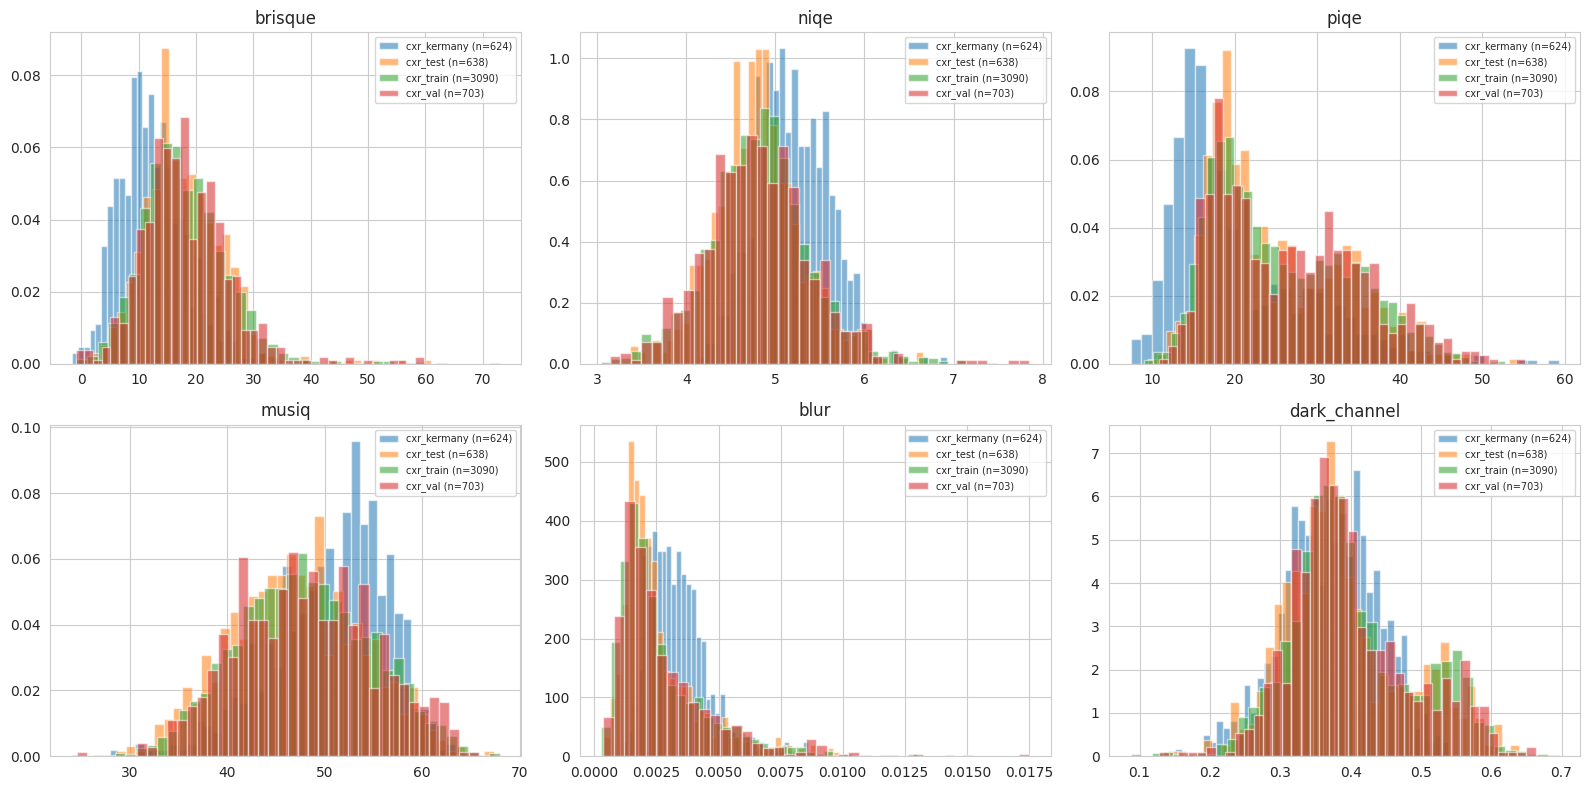

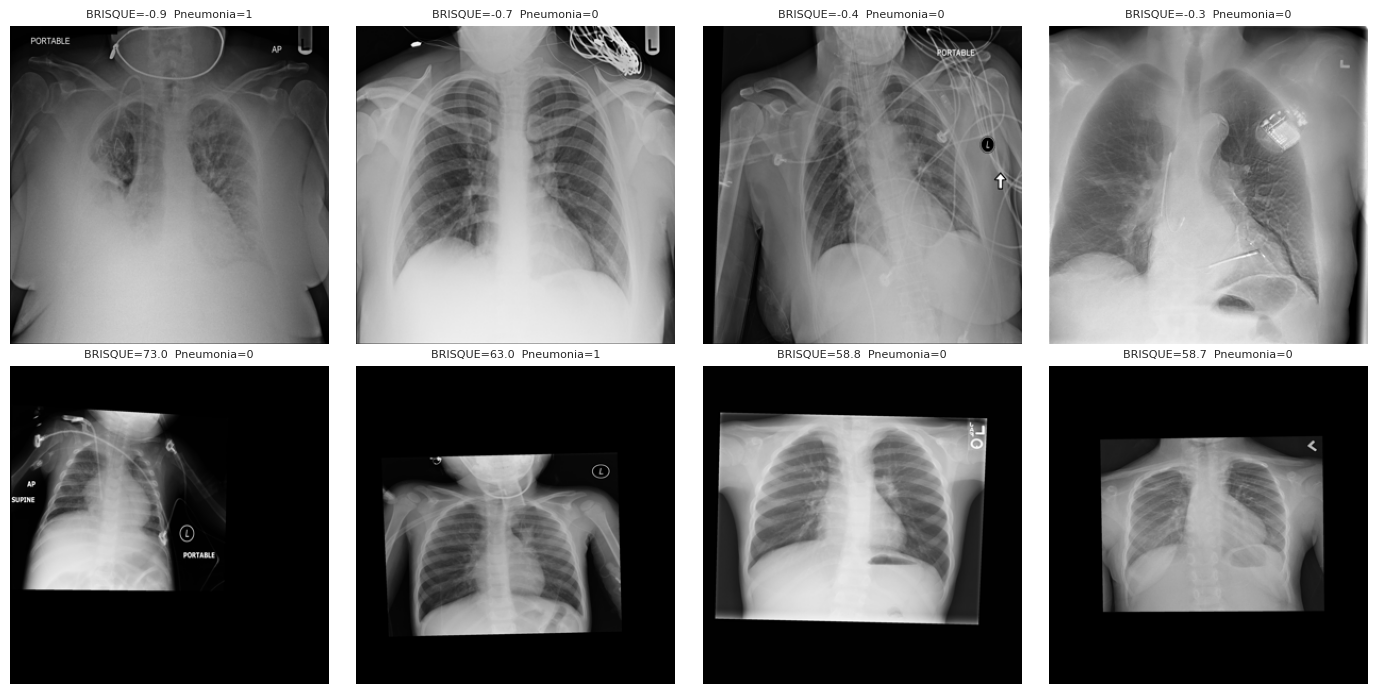

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, ft in zip(axes.ravel(), ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'dark_channel']):
    for src, d in F.groupby('source'):
        ax.hist(d[ft], bins=40, alpha=0.55, label=f'{src} (n={len(d)})', density=True)
    ax.set_title(ft); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig1cxr_degradation_distributions.png', dpi=200); plt.show()

tr_f = F[F.source == 'cxr_train']
ex = pd.concat([tr_f.nsmallest(4, 'brisque'), tr_f.nlargest(4, 'brisque')])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), ex.iterrows()):
    ax.imshow(Image.open(r['path']).convert('RGB').resize((300, 300))); ax.axis('off')
    ax.set_title(f"BRISQUE={r['brisque']:.1f}  Pneumonia={int(r['label'])}", fontsize=8)
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig1cxrb_clean_vs_noisy.png', dpi=200); plt.show()

## 4. Probe study (RQ1, CXR) — is pneumonia predictable from degradation alone?
5-fold CV on NIH train, shuffled negative control, external transfer to Kermany, prevalence-by-BRISQUE-bin curves. **Hypothesis (contrast with fundus): weaker or non-transferable signal — the shortcut setting.**

=== probe diagnostics ===
F source counts: {'cxr_train': 3090, 'cxr_val': 703, 'cxr_test': 638, 'cxr_kermany': 624}
                                       probe           value
                     NIH 5-fold AUC - LogReg 0.626 +/- 0.016
                        NIH 5-fold AUC - GBM 0.589 +/- 0.023
         NIH 5-fold AUC - SHUFFLED (control) 0.528 +/- 0.022
Kermany external AUC (from degradation only)           0.773


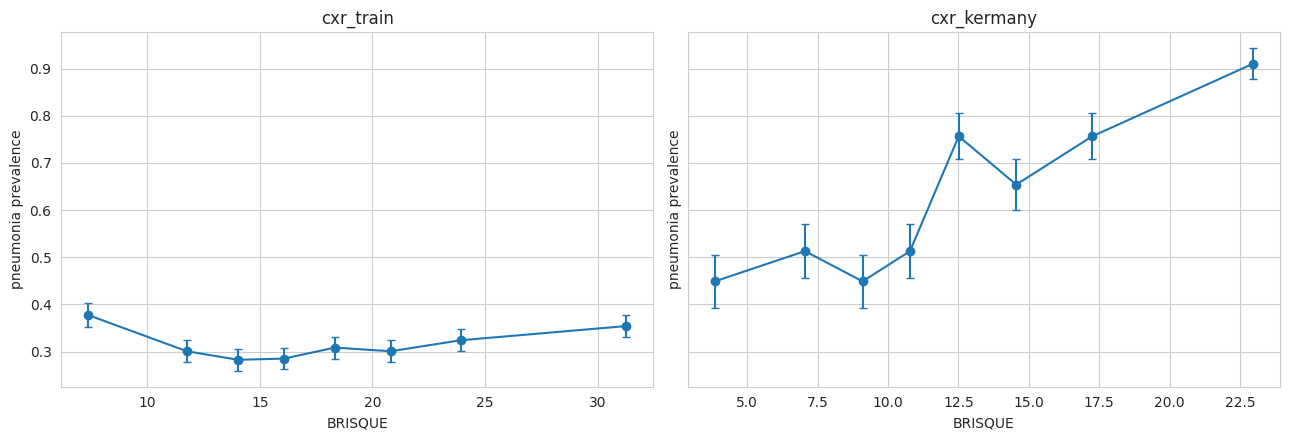

In [5]:
print('=== probe diagnostics ===')
print('F source counts:', F.source.value_counts().to_dict())
tr_mask = (F.source.values == 'cxr_train')
me_mask = (F.source.values == 'cxr_kermany')
assert tr_mask.sum() > 500, 'F has too few cxr_train rows - check Sections 1-2.'
assert me_mask.sum() > 100, 'F has no kermany rows - check Sections 1-2.'
ytr = F.label.values[tr_mask].astype(int)

mu, sd = F.loc[F.source == 'cxr_train', FEATS].mean(), F.loc[F.source == 'cxr_train', FEATS].std().replace(0, 1)
X = ((F[FEATS] - mu) / sd).values
assert not np.isnan(X).any(), 'NaN in feature matrix X.'

def cv_auc(Xm, y, model_fn, n_splits=5):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    aucs = []
    for tr_i, va_i in skf.split(Xm, y):
        m = model_fn(); m.fit(Xm[tr_i], y[tr_i])
        aucs.append(roc_auc_score(y[va_i], m.predict_proba(Xm[va_i])[:, 1]))
    return float(np.mean(aucs)), float(np.std(aucs))

probe_lr = cv_auc(X[tr_mask], ytr, lambda: LogisticRegression(max_iter=3000))
probe_gb = cv_auc(X[tr_mask], ytr, lambda: HistGradientBoostingClassifier(max_iter=300, random_state=SEED))

rng = np.random.default_rng(0)
Xsh = X.copy()
for j in range(Xsh.shape[1]):
    Xsh[:, j] = Xsh[rng.permutation(len(Xsh)), j]
shuf_lr = cv_auc(Xsh[tr_mask], ytr, lambda: LogisticRegression(max_iter=3000))

mm = LogisticRegression(max_iter=3000).fit(X[tr_mask], ytr)
ext_auc = roc_auc_score(F.label.values[me_mask], mm.predict_proba(X[me_mask])[:, 1])

probe_tbl = pd.DataFrame({
    'probe': ['NIH 5-fold AUC - LogReg', 'NIH 5-fold AUC - GBM', 'NIH 5-fold AUC - SHUFFLED (control)',
              'Kermany external AUC (from degradation only)'],
    'value': [f'{probe_lr[0]:.3f} +/- {probe_lr[1]:.3f}', f'{probe_gb[0]:.3f} +/- {probe_gb[1]:.3f}',
              f'{shuf_lr[0]:.3f} +/- {shuf_lr[1]:.3f}', f'{ext_auc:.3f}']})
print(probe_tbl.to_string(index=False))
probe_tbl.to_csv(f'{WORK}/results/table1cxr_probe.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, src in zip(axes, ['cxr_train', 'cxr_kermany']):
    d = F[F.source == src].copy()
    d['bin'] = pd.qcut(d['brisque'], 8, duplicates='drop')
    g = d.groupby('bin', observed=True).agg(prev=('label', 'mean'), n=('label', 'size'), brisque=('brisque', 'mean'))
    ax.errorbar(g['brisque'], g['prev'], yerr=np.sqrt(np.clip(g['prev'] * (1 - g['prev']) / g['n'], 0, None)),
                marker='o', capsize=3)
    ax.set_title(src); ax.set_xlabel('BRISQUE'); ax.set_ylabel('pneumonia prevalence')
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig2cxr_prevalence_vs_degradation.png', dpi=200); plt.show()

## 5. Models — 4 arms × 3 seeds (identical architecture to fundus arm)

In [6]:
import torch.nn.functional as TF  # 'F' is shadowed by the features DataFrame

qs = np.quantile(F.loc[tr_mask, 'brisque'], np.linspace(0, 1, 6))
F = F.copy()
F['deg_bucket'] = np.clip(np.digitize(F['brisque'], qs[1:-1]), 0, 4).astype(int)
deg_z_mu = F.loc[tr_mask, FEATS].mean().values.astype(np.float32)
deg_z_sd = F.loc[tr_mask, FEATS].std().replace(0, 1).values.astype(np.float32)

NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = T.Compose([T.Resize((256, 256)), T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
eval_tf  = T.Compose([T.Resize((256, 256)), T.CenterCrop(224), T.ToTensor(), NORM])

class RandomGamma:
    def __call__(self, img):
        a = np.asarray(img).astype(np.float32) / 255.
        g = math.exp(random.uniform(math.log(0.65), math.log(1.5)))
        return Image.fromarray((np.power(a, g) * 255).astype(np.uint8))
class RandomNoise:
    def __call__(self, img):
        a = np.asarray(img).astype(np.float32)
        a += np.random.normal(0, random.uniform(2, 12), a.shape)
        return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
class RandomBlur:
    def __call__(self, img):
        return img.filter(ImageFilter.GaussianBlur(random.uniform(0.5, 2.0)))
class RandomContrast:
    def __call__(self, img):
        return ImageEnhance.Contrast(img).enhance(random.uniform(0.6, 1.4))
aug_train_tf = T.Compose([T.Resize((256, 256)), RandomGamma(), RandomContrast(), RandomBlur(), RandomNoise(),
                          T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])

class CXRDS(torch.utils.data.Dataset):
    def __init__(self, df, tf):
        self.df = df.reset_index(drop=True); self.tf = tf
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = self.tf(Image.open(r['path']).convert('RGB'))
        deg = torch.tensor((np.array(r[FEATS].values, dtype=np.float32) - deg_z_mu) / deg_z_sd,
                           dtype=torch.float32)
        return img, int(r['label']), deg, int(r['deg_bucket'])

class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None

def make_model(mode):
    import timm
    bb = timm.create_model('resnet50', pretrained=True, num_classes=0).to(DEVICE)
    D = len(FEATS)
    ph = None
    if mode in ('baseline', 'aug'):
        head = nn.Linear(2048, 2).to(DEVICE); extra = [head]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    elif mode == 'harness':
        dml = nn.Sequential(nn.Linear(D, 64), nn.ReLU(), nn.Linear(64, 32)).to(DEVICE)
        head = nn.Linear(2048 + 32, 2).to(DEVICE); extra = [dml, head]
        def fwd(x, deg=None):
            f = bb(x); d = dml(deg)
            return head(torch.cat([f, d], 1)), f
    elif mode == 'suppress':
        head = nn.Linear(2048, 2).to(DEVICE)
        ph = nn.Linear(2048, 5).to(DEVICE); extra = [head, ph]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    else:
        raise ValueError(mode)
    return bb, fwd, extra, ph

SEEDS = [42, 7, 2024]
EPOCHS = 15

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def train_arm(mode, seed, epochs=EPOCHS, bs=32, lr_bb=3e-5, lr_head=1e-3):
    set_seed(seed)
    tr_ds = CXRDS(F[F.source == 'cxr_train'], aug_train_tf if mode == 'aug' else train_tf)
    va_ds = CXRDS(F[F.source == 'cxr_val'], eval_tf)
    tr_ld = torch.utils.data.DataLoader(tr_ds, batch_size=bs, shuffle=True, num_workers=2,
                                        pin_memory=True, drop_last=True)
    va_ld = torch.utils.data.DataLoader(va_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
    bb, fwd, extra, ph = make_model(mode)
    opt = torch.optim.AdamW([{'params': bb.parameters(), 'lr': lr_bb}] +
                            [{'params': m.parameters(), 'lr': lr_head} for m in extra], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    n_pos = int(tr_ds.df.label.sum()); n_neg = len(tr_ds.df) - n_pos
    ce = nn.CrossEntropyLoss(weight=torch.tensor([1.0, n_neg / max(1, n_pos)], device=DEVICE))
    best_auc, best_state = 0, None
    for ep in range(epochs):
        bb.train(); t0 = time.time(); tot = 0
        lam = float(ep) / max(1, epochs - 1) * 0.5
        for img, y, deg, bkt in tr_ld:
            img, y, deg, bkt = img.to(DEVICE), y.to(DEVICE), deg.to(DEVICE).float(), bkt.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda'):
                logits, f = fwd(img, deg)
                loss = ce(logits, y)
                if mode == 'suppress':
                    loss = loss + 0.5 * TF.cross_entropy(ph(GRL.apply(f, lam)), bkt)
            loss.backward(); opt.step(); tot += loss.item()
        sched.step()
        bb.eval(); ps, ys = [], []
        with torch.no_grad(), torch.autocast('cuda'):
            for img, y, deg, bkt in va_ld:
                logits, _ = fwd(img.to(DEVICE), deg.to(DEVICE).float())
                ps.append(logits.float().softmax(1)[:, 1].cpu()); ys.append(y)
        vauc = roc_auc_score(torch.cat(ys), torch.cat(ps))
        if vauc > best_auc:
            best_auc = vauc
            best_state = {k: v.detach().cpu().clone() for k, v in bb.state_dict().items()}
        print(f'  [{mode}|s{seed}] ep{ep+1}/{epochs} loss={tot/len(tr_ld):.4f} val_auc={vauc:.4f} '
              f'best={best_auc:.4f} ({time.time()-t0:.0f}s)')
    torch.save(best_state, f'{WORK}/ckpt/{mode}_s{seed}.pt')
    torch.cuda.empty_cache()
    return best_auc

val_aucs = []
for mode in ['baseline', 'harness', 'suppress', 'aug']:
    for seed in SEEDS:
        print(f'=== training {mode} | seed {seed} ===')
        val_aucs.append({'arm': mode, 'seed': seed, 'val_auc': train_arm(mode, seed)})
va_df = pd.DataFrame(val_aucs)
print(va_df.groupby('arm').val_auc.agg(['mean', 'std']).round(4))
va_df.to_csv(f'{WORK}/results/val_aucs_cxr.csv', index=False)
print('all arms x seeds trained (CXR).')

=== training baseline | seed 42 ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  [baseline|s42] ep1/15 loss=0.6816 val_auc=0.6333 best=0.6333 (72s)
  [baseline|s42] ep2/15 loss=0.6607 val_auc=0.6450 best=0.6450 (50s)
  [baseline|s42] ep3/15 loss=0.6517 val_auc=0.6543 best=0.6543 (50s)
  [baseline|s42] ep4/15 loss=0.6452 val_auc=0.6571 best=0.6571 (52s)
  [baseline|s42] ep5/15 loss=0.6332 val_auc=0.6722 best=0.6722 (51s)
  [baseline|s42] ep6/15 loss=0.6266 val_auc=0.6765 best=0.6765 (51s)
  [baseline|s42] ep7/15 loss=0.6151 val_auc=0.6837 best=0.6837 (51s)
  [baseline|s42] ep8/15 loss=0.6115 val_auc=0.6813 best=0.6837 (50s)
  [baseline|s42] ep9/15 loss=0.6056 val_auc=0.6840 best=0.6840 (50s)
  [baseline|s42] ep10/15 loss=0.6054 val_auc=0.6857 best=0.6857 (50s)
  [baseline|s42] ep11/15 loss=0.5988 val_auc=0.6869 best=0.6869 (51s)
  [baseline|s42] ep12/15 loss=0.5992 val_auc=0.6893 best=0.6893 (52s)
  [baseline|s42] ep13/15 loss=0.5934 val_auc=0.6903 best=0.6903 (53s)
  [baseline|s42] ep14/15 loss=0.5920 val_auc=0.6850 best=0.6903 (51s)
  [baseline|s42] ep15/15 loss

## 6. Evaluation (CXR) — same paper-grade metrics as fundus arm
Plus the **combined decision-rule figure**: merges these CXR deltas with your mounted fundus outputs (`table2b_deltas.csv`) into one fundus-vs-CXR comparison — the paper's central figure.

--- per-seed AUCs ---
     arm  seed  cxr_test  cxr_kermany
baseline    42     0.518        0.457
baseline     7     0.425        0.563
baseline  2024     0.528        0.546
 harness    42     0.547        0.322
 harness     7     0.543        0.630
 harness  2024     0.503        0.364
suppress    42     0.560        0.435
suppress     7     0.545        0.448
suppress  2024     0.489        0.378
     aug    42     0.422        0.556
     aug     7     0.536        0.794
     aug  2024     0.474        0.680
--- Table 2 (CXR): main results ---
     arm        eval   AUC  AUC_std_across_seeds  CI_lo  CI_hi   ECE   n
baseline    cxr_test 0.473                 0.057  0.422  0.523 0.217 638
baseline cxr_kermany 0.538                 0.057  0.491  0.582 0.123 624
 harness    cxr_test 0.557                 0.024  0.510  0.607 0.198 638
 harness cxr_kermany 0.390                 0.167  0.346  0.437 0.148 624
suppress    cxr_test 0.551                 0.037  0.501  0.599 0.206 638
suppress c

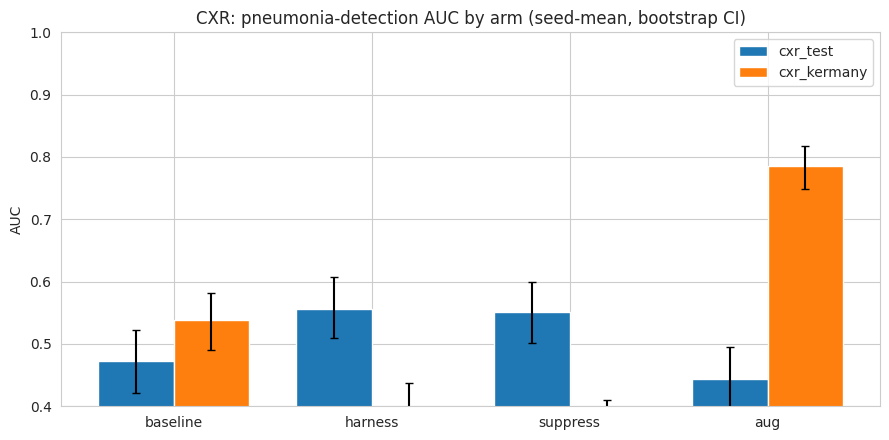

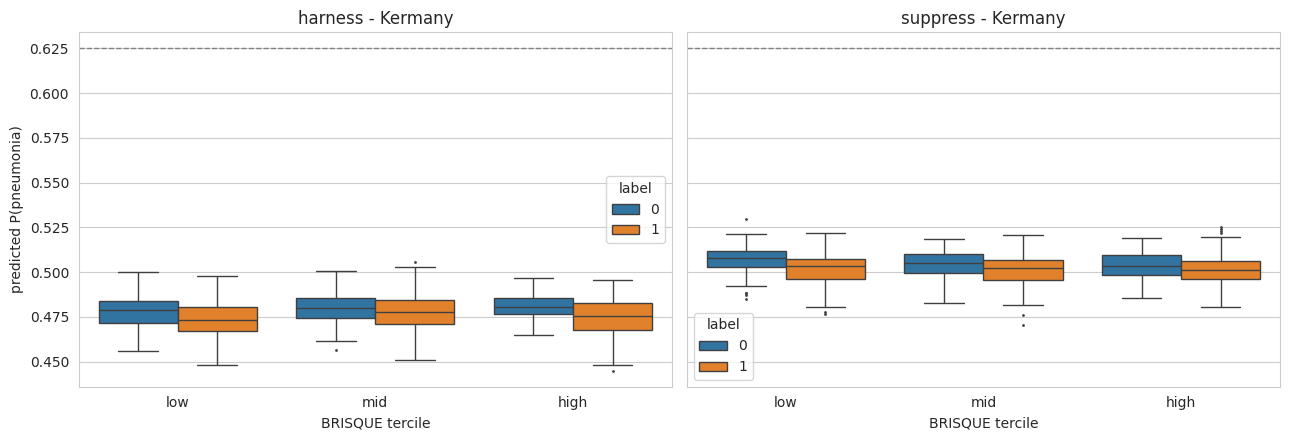

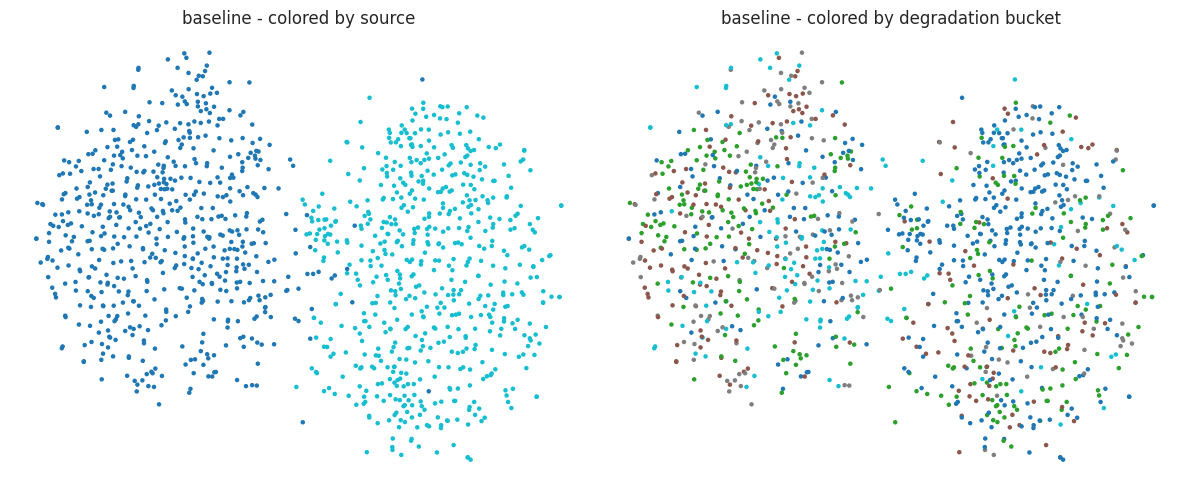

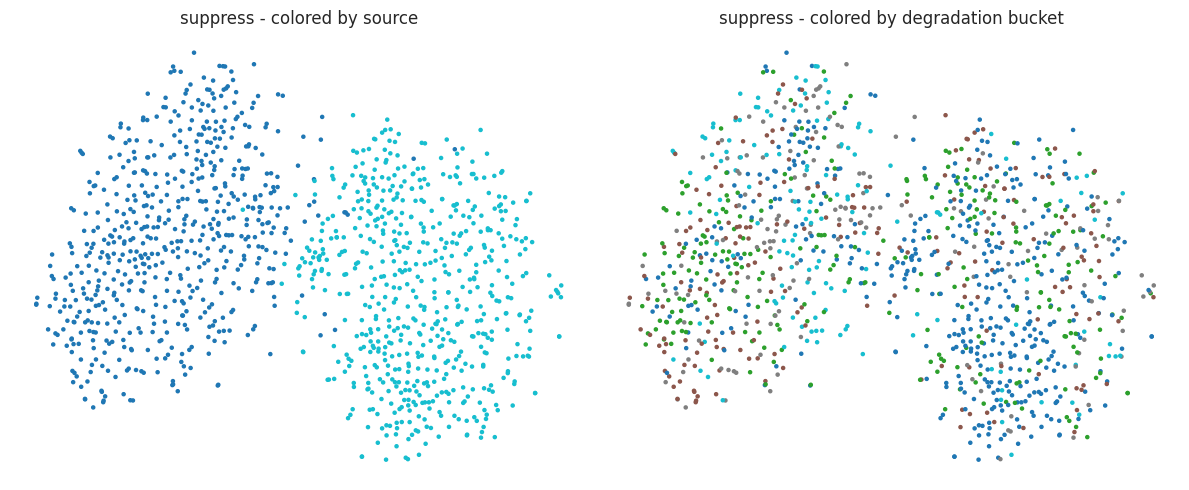

In [7]:
ARMS = ['baseline', 'harness', 'suppress', 'aug']
te_feat = F[F.source == 'cxr_test'].reset_index(drop=True)
me_feat = F[F.source == 'cxr_kermany'].reset_index(drop=True)
assert len(te_feat) > 100 and len(me_feat) > 100, 'feature frames missing - re-run Section 2.'
assert all(os.path.exists(f'{WORK}/ckpt/{m}_s{s}.pt') for m in ARMS for s in SEEDS), \
    'missing checkpoints - run Section 5 first.'

def boot_auc(y, p, n=2000, seed=1):
    rng = np.random.default_rng(seed)
    y = np.asarray(y); p = np.asarray(p)
    aucs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))

def paired_delta_auc(y, p1, p2, n=2000, seed=1):
    rng = np.random.default_rng(seed)
    y = np.asarray(y); p1 = np.asarray(p1); p2 = np.asarray(p2)
    ds = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        ds.append(roc_auc_score(y[idx], p1[idx]) - roc_auc_score(y[idx], p2[idx]))
    d = np.asarray(ds)
    lo, hi = np.percentile(d, [2.5, 97.5])
    p_val = 2.0 * min((d <= 0).mean(), (d >= 0).mean())
    return float(d.mean()), float(lo), float(hi), float(min(1.0, p_val))

def split_half_probe(X, y, n_splits=2):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    accs = []
    for tr_i, te_i in skf.split(X, y):
        m = MLPClassifier((128, 64), max_iter=300, random_state=SEED)
        m.fit(X[tr_i], y[tr_i])
        accs.append(accuracy_score(y[te_i], m.predict(X[te_i])))
    return float(np.mean(accs))

def ece(y, p, n_bins=10):
    y = np.asarray(y); p = np.asarray(p)
    edges = np.linspace(0, 1, n_bins + 1); e = 0.0
    for i in range(n_bins):
        m = (p > edges[i]) & (p <= edges[i + 1]) if i else (p <= edges[i + 1])
        if m.sum():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)

@torch.no_grad()
def infer(mode, seed, df):
    ds = CXRDS(df, eval_tf)
    ld = torch.utils.data.DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
    bb, fwd, extra, ph = make_model(mode)
    bb.load_state_dict(torch.load(f'{WORK}/ckpt/{mode}_s{seed}.pt', map_location=DEVICE))
    bb.eval(); ps, fs = [], []
    for img, y, deg, bkt in ld:
        with torch.autocast('cuda'):
            logits, f = fwd(img.to(DEVICE), deg.to(DEVICE).float())
        ps.append(logits.float().softmax(1)[:, 1].cpu()); fs.append(f.float().cpu())
    return torch.cat(ps).numpy(), torch.cat(fs).numpy()

seed_probs, seed_feats, seed_aucs = {}, {}, []
for mode in ARMS:
    te_ps, me_ps, te_fs, me_fs = [], [], [], []
    for seed in SEEDS:
        p_te, f_te = infer(mode, seed, te_feat)
        p_me, f_me = infer(mode, seed, me_feat)
        te_ps.append(p_te); me_ps.append(p_me); te_fs.append(f_te); me_fs.append(f_me)
        seed_aucs.append({'arm': mode, 'seed': seed,
                          'cxr_test': roc_auc_score(te_feat.label.values, p_te),
                          'cxr_kermany': roc_auc_score(me_feat.label.values, p_me)})
    seed_probs[mode] = {'cxr_test': np.mean(te_ps, axis=0), 'cxr_kermany': np.mean(me_ps, axis=0)}
    seed_feats[mode] = (np.mean(te_fs, axis=0), np.mean(me_fs, axis=0))
    torch.cuda.empty_cache()

sa = pd.DataFrame(seed_aucs)
print('--- per-seed AUCs ---')
print(sa.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
sa.to_csv(f'{WORK}/results/table2cxr_seeds.csv', index=False)

results = []
for mode in ARMS:
    for tag, y in [('cxr_test', te_feat.label.values), ('cxr_kermany', me_feat.label.values)]:
        p = seed_probs[mode][tag]
        auc = roc_auc_score(y, p); lo, hi = boot_auc(y, p)
        results.append({'arm': mode, 'eval': tag, 'AUC': auc,
                        'AUC_std_across_seeds': sa[sa.arm == mode][tag].std(),
                        'CI_lo': lo, 'CI_hi': hi, 'ECE': ece(y, p), 'n': len(y)})
res = pd.DataFrame(results)
print('--- Table 2 (CXR): main results ---')
print(res.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
res.to_csv(f'{WORK}/results/table2cxr_main.csv', index=False)

deltas = []
for tag, y in [('cxr_test', te_feat.label.values), ('cxr_kermany', me_feat.label.values)]:
    for a, b in [('harness', 'baseline'), ('suppress', 'baseline'), ('aug', 'baseline'),
                 ('suppress', 'harness'), ('aug', 'harness'), ('aug', 'suppress')]:
        m, lo, hi, pv = paired_delta_auc(y, seed_probs[a][tag], seed_probs[b][tag])
        deltas.append({'eval': tag, 'comparison': f'{a} - {b}', 'dAUC': m, 'CI_lo': lo, 'CI_hi': hi,
                       'p_value': pv})
delt = pd.DataFrame(deltas)
print('--- Table 2b (CXR): paired dAUC ---')
print(delt.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
delt.to_csv(f'{WORK}/results/table2bcxr_deltas.csv', index=False)

me_f = F[F.source == 'cxr_kermany'].copy()
me_f['terc'] = pd.qcut(me_f['brisque'], 3, labels=['low', 'mid', 'high'])
terc_rows = []
for mode in ARMS:
    p_me = seed_probs[mode]['cxr_kermany']
    for t in ['low', 'mid', 'high']:
        m = (me_f['terc'].values == t)
        yy = me_feat.label.values[m]
        if m.sum() > 10 and 0 < yy.sum() < m.sum():
            terc_rows.append({'arm': mode, 'quality_tercile': t,
                              'AUC': roc_auc_score(yy, p_me[m]), 'n': int(m.sum())})
terc = pd.DataFrame(terc_rows)
print('--- Table 3 (CXR): kermany terciles ---')
print(terc.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
terc.to_csv(f'{WORK}/results/table3cxr_terciles.csv', index=False)

fr = []
for mode in ARMS:
    f_te, f_me = seed_feats[mode]
    n_te = min(1000, len(f_te)); n_me = min(1000, len(f_me))
    Xd = np.vstack([f_te[:n_te], f_me[:n_me]]); yd = np.array([0] * n_te + [1] * n_me)
    dom_acc = split_half_probe(Xd, yd)
    Xq = np.vstack([f_te, f_me])
    bq = np.concatenate([te_feat.deg_bucket.values, me_feat.deg_bucket.values])
    deg_acc = split_half_probe(Xq, bq)
    fr.append({'arm': mode, 'domain_probe_acc_heldout': dom_acc,
               'degradation_probe_acc_heldout': deg_acc,
               'task_AUC_kermany': res[(res['arm'] == mode) & (res['eval'] == 'cxr_kermany')]['AUC'].iloc[0]})
fr = pd.DataFrame(fr)
print('--- Table 4 (CXR): forensic probes (held-out) ---')
print(fr.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
fr.to_csv(f'{WORK}/results/table4cxr_forensic_probes.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(4); w = 0.38
for tag, off in [('cxr_test', -w / 2), ('cxr_kermany', w / 2)]:
    d = res[res['eval'] == tag].set_index('arm').loc[ARMS]
    ax.bar(x + off, d.AUC, w, yerr=[d.AUC - d.CI_lo, d.CI_hi - d.AUC], capsize=3, label=tag)
ax.set_xticks(x); ax.set_xticklabels(ARMS)
ax.set_ylim(0.4, 1.0); ax.set_ylabel('AUC'); ax.legend(); ax.set_title('CXR: pneumonia-detection AUC by arm (seed-mean, bootstrap CI)')
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig3cxr_auc_arms.png', dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, mode in zip(axes, ['harness', 'suppress']):
    dfp = pd.DataFrame({'tercile': me_f['terc'].astype(str).values,
                        'label': me_feat.label.values,
                        'prob': seed_probs[mode]['cxr_kermany']})
    sns.boxplot(data=dfp, x='tercile', y='prob', hue='label', ax=ax, fliersize=1)
    ax.axhline(me_feat.label.mean(), ls='--', c='gray', lw=1)
    ax.set_title(f'{mode} - Kermany'); ax.set_xlabel('BRISQUE tercile'); ax.set_ylabel('predicted P(pneumonia)')
plt.tight_layout(); plt.savefig(f'{WORK}/results/fig5cxr_score_by_tercile.png', dpi=200); plt.show()

for mode in ['baseline', 'suppress']:
    try:
        f_te, f_me = seed_feats[mode]
        rng = np.random.default_rng(0)
        n_sub = int(min(600, len(f_te), len(f_me)))
        if n_sub < 40:
            print(f'[t-SNE] skipped for {mode}: only {n_sub} samples')
            continue
        idx_t = rng.choice(len(f_te), n_sub, replace=False)
        idx_m = rng.choice(len(f_me), n_sub, replace=False)
        X = np.vstack([f_te[idx_t], f_me[idx_m]])
        z = TSNE(n_components=2, perplexity=min(30, max(5, n_sub // 4)),
                 random_state=SEED, init='pca').fit_transform(X)
        src_c = np.array([0] * n_sub + [1] * n_sub)
        bkt = np.concatenate([te_feat.deg_bucket.values[idx_t], me_feat.deg_bucket.values[idx_m]])
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        for ax, cc, title in [(axes[0], src_c, 'source'), (axes[1], bkt, 'degradation bucket')]:
            ax.scatter(z[:, 0], z[:, 1], c=cc, s=5, cmap='tab10')
            ax.set_title(f'{mode} - colored by {title}'); ax.axis('off')
        plt.tight_layout(); plt.savefig(f'{WORK}/results/fig4cxr_tsne_{mode}.png', dpi=200); plt.show()
    except Exception as e:
        print(f'[t-SNE] failed for {mode}: {e} (non-fatal, continuing)')

loading fundus deltas from: /kaggle/input/notebooks/kazirifatahmed/midl-v2/results/table2b_deltas.csv
       eval          comparison    dAUC   CI_lo   CI_hi  p_value                  dataset      eval_group  sig
 aptos_test  harness - baseline -0.2033 -0.2920 -0.1204   0.0000 Fundus (APTOS->Messidor) in-distribution True
 aptos_test suppress - baseline -0.1842 -0.2686 -0.0995   0.0000 Fundus (APTOS->Messidor) in-distribution True
   messidor  harness - baseline  0.0696  0.0260  0.1127   0.0050 Fundus (APTOS->Messidor)        external True
   messidor suppress - baseline  0.0739  0.0310  0.1161   0.0010 Fundus (APTOS->Messidor)        external True
   cxr_test  harness - baseline  0.0850  0.0112  0.1610   0.0270       CXR (NIH->Kermany) in-distribution True
   cxr_test suppress - baseline  0.0782  0.0063  0.1502   0.0260       CXR (NIH->Kermany) in-distribution True
cxr_kermany  harness - baseline -0.1472 -0.2158 -0.0825   0.0000       CXR (NIH->Kermany)        external True
cxr_kerman

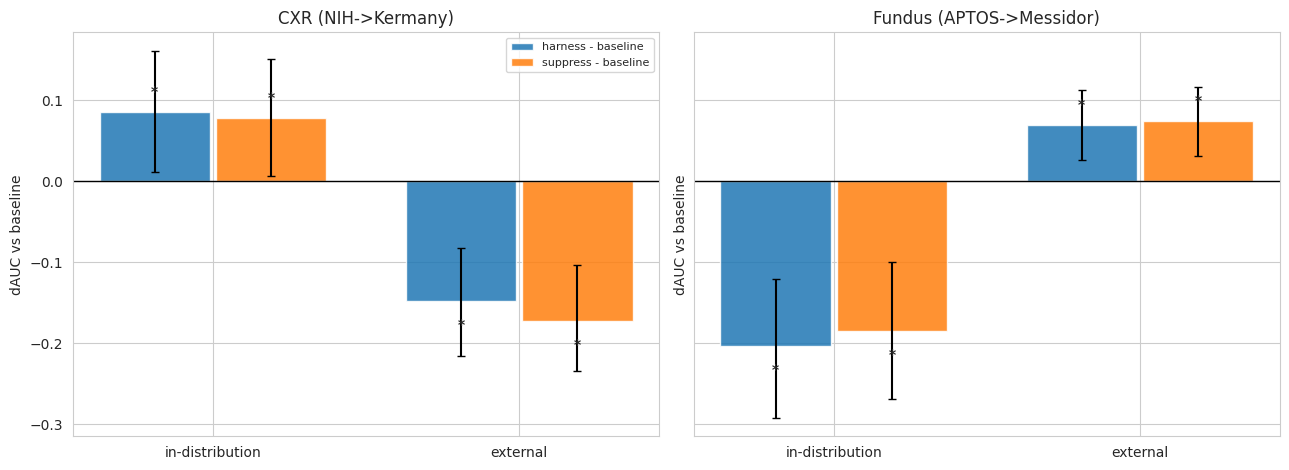

combined decision-rule figure saved.


In [8]:
# ---------- Combined decision-rule figure: fundus vs CXR ----------
fundus_paths = sorted(glob.glob('/kaggle/input/notebooks/kazirifatahmed/midl-v2/results/table2b_deltas.csv', recursive=True))
if not fundus_paths:
    print('Fundus table2b_deltas.csv not found under /kaggle/input - skipping combined figure.')
    print('(Mount the OUTPUT of the fundus notebook as an input dataset to enable it.)')
else:
    fp = fundus_paths[0]
    print('loading fundus deltas from:', fp)
    fd = pd.read_csv(fp)
    fd['dataset'] = 'Fundus (APTOS->Messidor)'
    cd = delt.copy()
    cd['dataset'] = 'CXR (NIH->Kermany)'
    comb = pd.concat([fd, cd], ignore_index=True)
    comb = comb[comb['comparison'].isin(['harness - baseline', 'suppress - baseline'])].copy()
    comb['eval_group'] = comb['eval'].map({'aptos_test': 'in-distribution', 'messidor': 'external',
                                           'cxr_test': 'in-distribution', 'cxr_kermany': 'external'})
    comb['sig'] = comb['p_value'] < 0.05
    comb.to_csv(f'{WORK}/results/table6_decision_rule.csv', index=False)
    print(comb.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    for ax, (dsname, d) in zip(axes, comb.groupby('dataset')):
        for off, comp, col in [(-0.19, 'harness - baseline', '#1f77b4'), (0.19, 'suppress - baseline', '#ff7f0e')]:
            dd = d[d['comparison'] == comp].set_index('eval_group').reindex(['in-distribution', 'external'])
            ax.bar(np.arange(2) + off, dd['dAUC'], 0.36, yerr=[dd['dAUC'] - dd['CI_lo'], dd['CI_hi'] - dd['dAUC']],
                   capsize=3, label=comp, color=col, alpha=0.85)
            for i, (v, s) in enumerate(zip(dd['dAUC'], dd['sig'])):
                ax.text(i + off, v + (0.02 if v >= 0 else -0.035), '*' if s else 'ns',
                        ha='center', fontsize=10, fontweight='bold')
        ax.axhline(0, c='k', lw=1)
        ax.set_xticks(np.arange(2)); ax.set_xticklabels(['in-distribution', 'external'])
        ax.set_title(dsname); ax.set_ylabel('dAUC vs baseline')
    axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f'{WORK}/results/fig6_decision_rule.png', dpi=200); plt.show()
    print('combined decision-rule figure saved.')

## 7. Reading the CXR results (and how they complete the paper)
- **Table 1 (CXR) / Fig 2 (CXR)**: is pneumonia predictable from degradation? Compare the probe AUC and the prevalence curves against the fundus arm — the *shape and transferability* of the association is the contrast.
- **Table 2/2b (CXR)**: hypothesis — harness may gain in-distribution but the gain should NOT transfer to Kermany (degradation is site/protocol-confounded rather than physiological), and suppress should be the most stable arm externally. If so, fundus (biomarker: harness wins where it's causal) vs CXR (shortcut: harness fails to transfer) = the decision rule.
- **Known limitations to state honestly**: (1) Kermany is pediatric vs NIH adult — age is a strong confound, which is *part of the story* (distribution shift) but must be acknowledged; (2) pneumonia prevalence differs ~50x between sets (1.3% vs ~60%) — prevalence shift affects AUC and calibration, interpret ECE carefully; (3) NIH images contain burned-in text markers — a known shortcut channel, which is precisely why this arm tests "shortcut" behavior.
- **Next**: freeze all numbers, then write Results & Discussion (fundus + CXR + decision rule + limitations), then full LaTeX assembly.